# Chapter 3: Efficient Solving Under Multiple Constraints

Companion code for *Robust Adaptive Beamforming and Its Applications* by Ayman Elnashar (Wiley, forthcoming).

This notebook reproduces every simulation figure of Chapter 3 (Figures 3.1–3.14), Tables 3.2–3.6 and the numbers quoted in the text. The chapter develops **DAS-MBWC**, the dual-space active-set multiple-beam worst-case beamformer: a robust LCMV design with several worst-case constraints

$$\min_{\mathbf w}\ \mathbf w^H\mathbf R\mathbf w\quad\text{s.t.}\quad \mathrm{Re}\{\mathbf w^H\mathbf l_i\}\ \ge\ \nu_i\|\mathbf w\| + 1,\qquad i = 1,\dots,N,$$

solved once per snapshot by a gradient step followed by a closed-form correction on the constraints that the gradient step violates (Algorithm 3.1).

The chapter builds on the article: A. Elnashar, "Selective Constraint Enforcement in Robust LCMV Beamforming: A Dual-Space Active-Set Method," submitted.

## Configuration

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # chapter folder, so that `ch3dasmbwc` imports without installation
QUICK = False                  # True: two Monte Carlo trials per point (smoke test)
FIGDIR = '../figures'          # relative to notebooks/
USE_CACHE = os.path.isdir(os.path.join(FIGDIR, 'data'))   # reuse simulation data saved by scripts/generate_figures.py
os.environ.update(QUICK='1' if QUICK else '0', FIGDIR=FIGDIR, RAB_CACHE='1' if USE_CACHE else '0', RAB_INLINE='1')
print('re-plot from saved data' if USE_CACHE else 'simulating', '| QUICK =', QUICK)

re-plot from saved data | QUICK = False


## Library

`ch3dasmbwc.algorithms` holds the beamformers: standard and diagonally loaded MVDR, the exact single worst-case beamformer WC-MVDR [6], the adaptive single-WC beamformer [12], the covariance-reconstruction comparator after Gu and Leshem [22], DAS-MBWC (Algorithm 3.1) with its all-constraint ablation, the exact conic solution of the multi-constraint problem (3.12) and the Slater margin (3.A.4). `ch3dasmbwc.scenarios` holds the settings of Section 3.6 and one runner per experiment, each with fixed seeds; `ch3dasmbwc.figures` draws the figures and collects the tables.

In [2]:
import json
from ch3dasmbwc.figures import *
print('Monte Carlo counts:', NR)

def show(key):
    print(json.dumps(RESULTS[key], indent=1, ensure_ascii=False, default=str))

Monte Carlo counts: {'snap': 25, 'sweep': 25, 'sens': 15, 'errors': 20, 'size': 15, 'stab': 25, 'long': 5, 'long_K': 3000, 'abl': 25, 'mc': 200, 't3': 25, 't5': 25, 'signed': 25, 'time_rep': 5, 't4_rep': 10}


## Settings (Section 3.6)

M = 16 half-wavelength ULA; SOI at broadside, SNR 5 dB; interferers at 45° and −60°, INR 10 dB; noise 0 dB per element. Adaptive recursions: R(0) = I, η = 0.97. Batch beamformers: EWMA covariance with weight 0.99. ζ = 3.8. Constraint grid [θ₀, θ₀ − 2°, θ₀ + 2°, θ₀ − 4°] about the presumed direction θ₀, reference bounds ν₀ = [1.9, 1.5, 1.5, 1.1]. Bound adaptation (3.20) every 30 snapshots after a 50-snapshot warm-up, smoothing weight 0.8, clipping range [0.5, 2.0]. DL-MVDR loading 2σ². Reconstruction sector ±6° about the presumed direction. 300 snapshots and 25 trials per scenario.

## Figure 3.1: SINR versus snapshots, 2° mismatch, point source

Inside the worst-case ball the single worst-case beamformers and the reconstruction comparator lead DAS-MBWC.

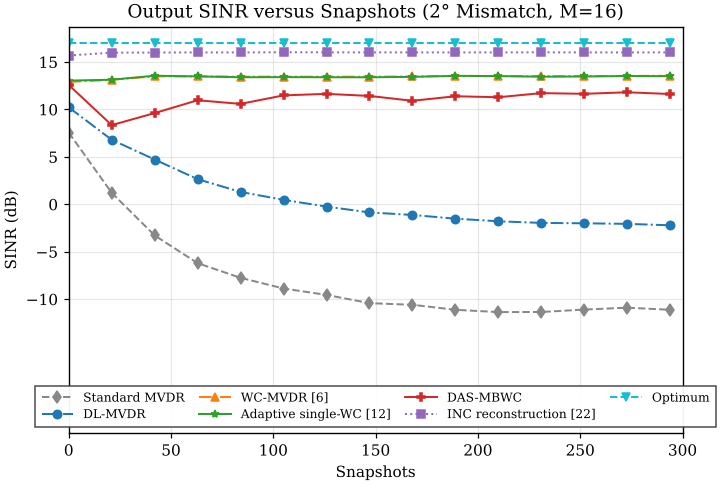

{
 "scenario": "2° point source",
 "final_snapshot_sinr_dB": {
  "Standard MVDR": -11.03,
  "DL-MVDR": -2.22,
  "WC-MVDR [6]": 13.55,
  "Adaptive single-WC [12]": 13.54,
  "DAS-MBWC": 11.63,
  "INC reconstruction [22]": 16.02,
  "Optimum": 17.02
 }
}


In [3]:
fig_3_1()
show('Fig3.1')

## Figure 3.2: steady-state beam patterns, 5° mismatch

One realization of 500 snapshots; green dotted line: true SOI at 0°, red dotted line: presumed direction 5°.

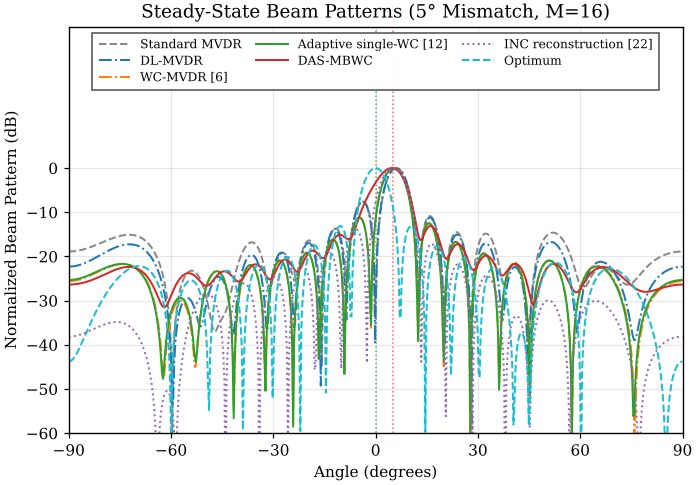

{
 "null_depth_dB_at_interferers": {
  "Standard MVDR": {
   "45°": -42.8,
   "-60°": -41.5
  },
  "DL-MVDR": {
   "45°": -43.1,
   "-60°": -43.0
  },
  "WC-MVDR [6]": {
   "45°": -39.6,
   "-60°": -33.6
  },
  "Adaptive single-WC [12]": {
   "45°": -41.9,
   "-60°": -32.6
  },
  "DAS-MBWC": {
   "45°": -28.0,
   "-60°": -28.9
  },
  "INC reconstruction [22]": {
   "45°": -61.5,
   "-60°": -52.4
  },
  "Optimum": {
   "45°": -68.0,
   "-60°": -77.9
  }
 }
}


In [4]:
fig_3_2()
show('Fig3.2')

## Figure 3.3: SINR versus snapshots, 5° mismatch, point source

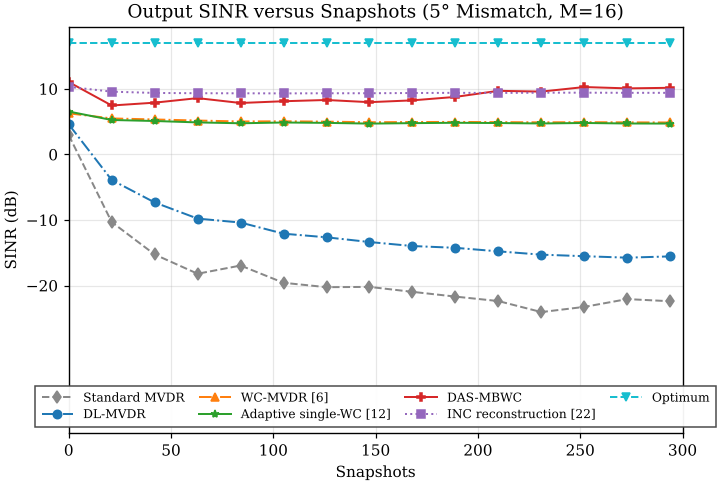

{
 "scenario": "5° point source",
 "final_snapshot_sinr_dB": {
  "Standard MVDR": -22.11,
  "DL-MVDR": -15.68,
  "WC-MVDR [6]": 4.89,
  "Adaptive single-WC [12]": 4.76,
  "DAS-MBWC": 10.21,
  "INC reconstruction [22]": 9.41,
  "Optimum": 17.02
 }
}


In [5]:
fig_3_3()
show('Fig3.3')

## Figure 3.4: SINR versus snapshots, 2° mismatch, small angular spread

Rays at 0°, +4° and −3° with amplitudes 1, 0.4 and 0.4; the phases of the secondary rays are redrawn at every snapshot, so the rays add in power.

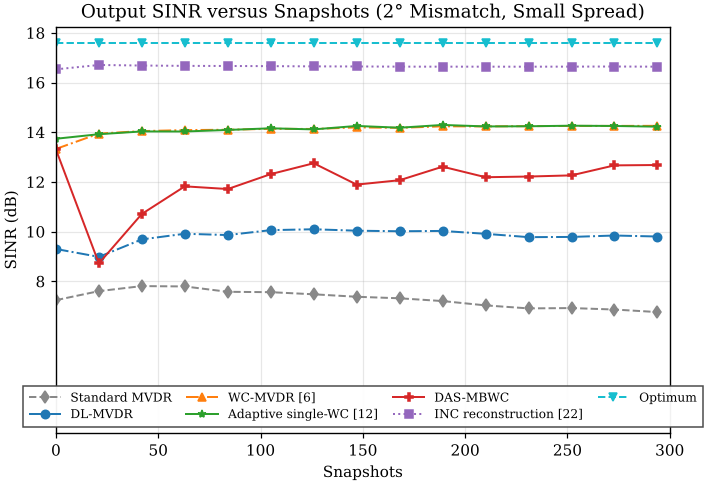

{
 "scenario": "2° sm. spread",
 "final_snapshot_sinr_dB": {
  "Standard MVDR": 6.7,
  "DL-MVDR": 9.84,
  "WC-MVDR [6]": 14.24,
  "Adaptive single-WC [12]": 14.19,
  "DAS-MBWC": 12.81,
  "INC reconstruction [22]": 16.64,
  "Optimum": 17.6
 }
}


In [6]:
fig_3_4()
show('Fig3.4')

## Figure 3.5: SINR versus snapshots, 5° mismatch, small angular spread

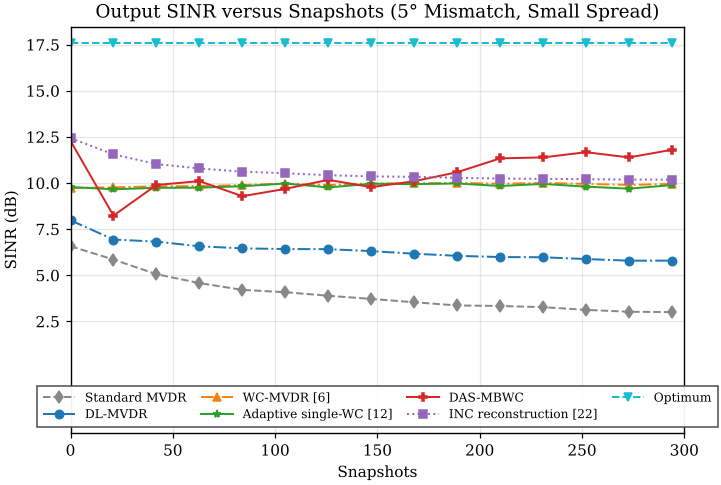

{
 "scenario": "5° sm. spread",
 "final_snapshot_sinr_dB": {
  "Standard MVDR": 3.01,
  "DL-MVDR": 5.79,
  "WC-MVDR [6]": 9.97,
  "Adaptive single-WC [12]": 9.9,
  "DAS-MBWC": 11.45,
  "INC reconstruction [22]": 10.17,
  "Optimum": 17.6
 }
}


In [7]:
fig_3_5()
show('Fig3.5')

## Figure 3.6: SINR versus snapshots, 7° mismatch, point source

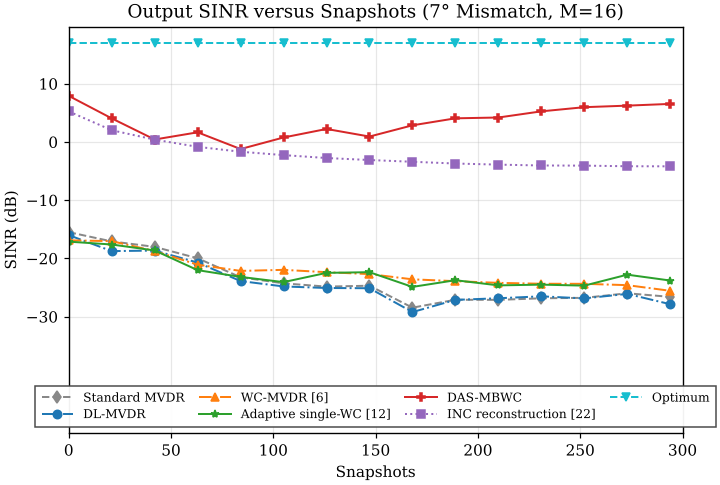

{
 "scenario": "7° point source",
 "final_snapshot_sinr_dB": {
  "Standard MVDR": -25.1,
  "DL-MVDR": -24.81,
  "WC-MVDR [6]": -25.65,
  "Adaptive single-WC [12]": -23.37,
  "DAS-MBWC": 6.57,
  "INC reconstruction [22]": -4.23,
  "Optimum": 17.02
 }
}


In [8]:
fig_3_6()
show('Fig3.6')

## Figure 3.7: SINR versus snapshots, 5° mismatch, large angular spread

Rays at 0° (direct), −25° (amplitude 0.5) and +35° (amplitude 0.3).

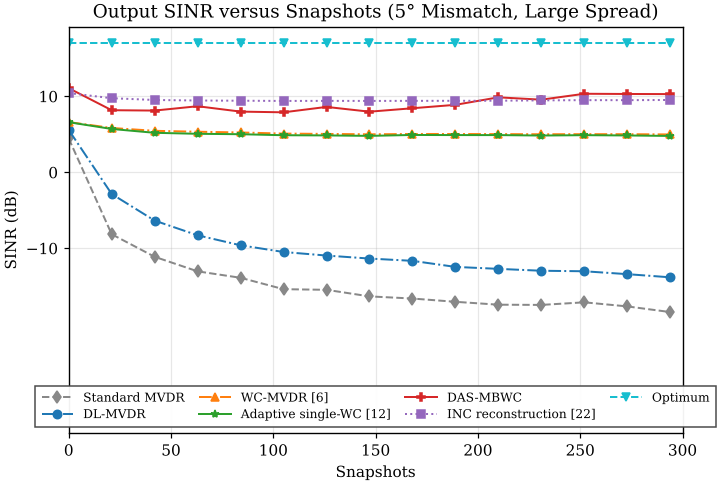

{
 "scenario": "5° lg. spread",
 "final_snapshot_sinr_dB": {
  "Standard MVDR": -18.26,
  "DL-MVDR": -13.85,
  "WC-MVDR [6]": 4.98,
  "Adaptive single-WC [12]": 4.77,
  "DAS-MBWC": 10.32,
  "INC reconstruction [22]": 9.55,
  "Optimum": 17.04
 }
}


In [9]:
fig_3_7()
show('Fig3.7')

## Figure 3.8: SINR versus snapshots, 7° mismatch, large angular spread

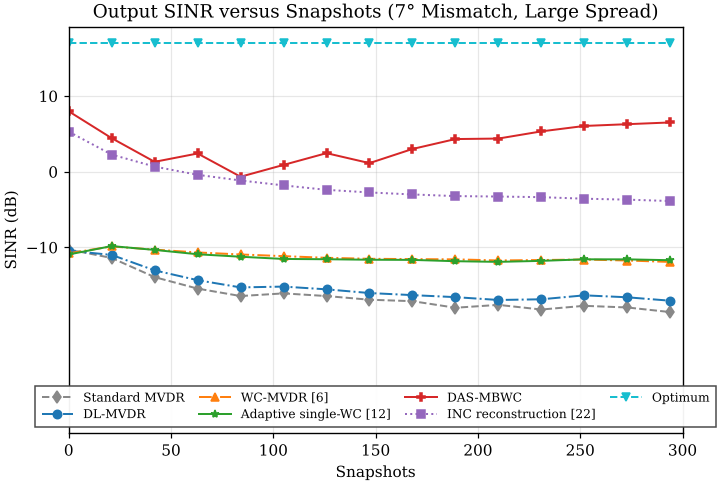

{
 "scenario": "7° lg. spread",
 "final_snapshot_sinr_dB": {
  "Standard MVDR": -18.72,
  "DL-MVDR": -17.34,
  "WC-MVDR [6]": -12.0,
  "Adaptive single-WC [12]": -11.81,
  "DAS-MBWC": 6.43,
  "INC reconstruction [22]": -4.01,
  "Optimum": 17.04
 }
}


In [10]:
fig_3_8()
show('Fig3.8')

## Figure 3.9: SINR versus mismatch angle, point source

25 trials of 300 snapshots per angle.

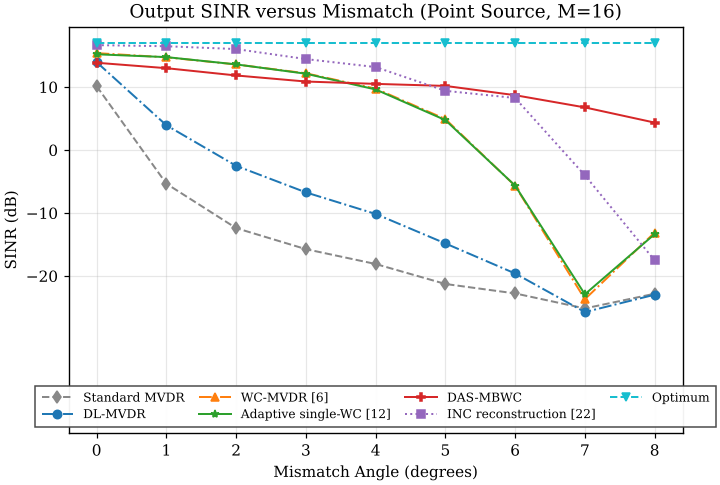

{
 "mismatch_deg": [
  0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8
 ],
 "sinr_dB": {
  "Standard MVDR": [
   10.14,
   -5.35,
   -12.4,
   -15.74,
   -18.09,
   -21.27,
   -22.77,
   -25.15,
   -22.81
  ],
  "DL-MVDR": [
   13.96,
   3.94,
   -2.51,
   -6.72,
   -10.15,
   -14.83,
   -19.6,
   -25.73,
   -22.97
  ],
  "WC-MVDR [6]": [
   15.39,
   14.72,
   13.59,
   12.19,
   9.75,
   4.92,
   -5.68,
   -23.69,
   -13.1
  ],
  "Adaptive single-WC [12]": [
   15.2,
   14.76,
   13.6,
   12.12,
   9.62,
   4.75,
   -5.65,
   -22.9,
   -13.35
  ],
  "DAS-MBWC": [
   13.86,
   13.0,
   11.84,
   10.88,
   10.51,
   10.18,
   8.71,
   6.77,
   4.36
  ],
  "INC reconstruction [22]": [
   16.66,
   16.48,
   16.03,
   14.44,
   13.18,
   9.4,
   8.27,
   -4.01,
   -17.51
  ],
  "Optimum": [
   17.02,
   17.02,
   17.02,
   17.02,
   17.02,
   17.02,
   17.02,
   17.02,
   17.02
  ]
 },
 "all_constraint_ablation_dB": [
  12.76,
  12.96,
  11.84,
  10.88,
  10.19,
  9.85,
  9.45,
  8.77,
  7.47


In [11]:
fig_3_9()
show('Fig3.9')

## Figure 3.10: SINR versus mismatch angle, small angular spread

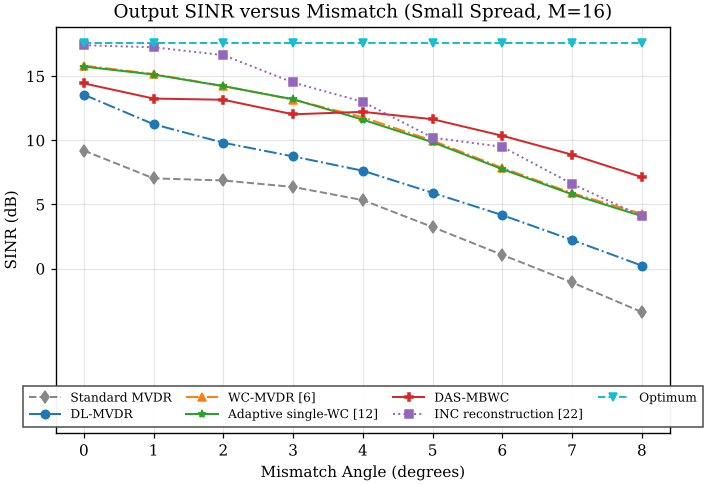

{
 "mismatch_deg": [
  0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8
 ],
 "sinr_dB": {
  "Standard MVDR": [
   9.21,
   7.03,
   6.87,
   6.37,
   5.34,
   3.24,
   1.07,
   -1.07,
   -3.39
  ],
  "DL-MVDR": [
   13.56,
   11.25,
   9.81,
   8.75,
   7.63,
   5.91,
   4.17,
   2.23,
   0.24
  ],
  "WC-MVDR [6]": [
   15.82,
   15.17,
   14.24,
   13.17,
   11.8,
   9.97,
   7.85,
   5.89,
   4.27
  ],
  "Adaptive single-WC [12]": [
   15.75,
   15.13,
   14.22,
   13.2,
   11.61,
   9.86,
   7.75,
   5.79,
   4.09
  ],
  "DAS-MBWC": [
   14.44,
   13.26,
   13.16,
   12.03,
   12.22,
   11.65,
   10.36,
   8.88,
   7.13
  ],
  "INC reconstruction [22]": [
   17.41,
   17.25,
   16.64,
   14.51,
   13.0,
   10.21,
   9.49,
   6.61,
   4.08
  ],
  "Optimum": [
   17.6,
   17.6,
   17.6,
   17.6,
   17.6,
   17.6,
   17.6,
   17.6,
   17.6
  ]
 },
 "all_constraint_ablation_dB": [
  13.55,
  13.23,
  13.06,
  11.97,
  11.37,
  11.2,
  10.29,
  9.74,
  8.47
 ]
}


In [12]:
fig_3_10()
show('Fig3.10')

## Figure 3.11: array imperfections at 5° mismatch

Element gain, phase and position errors (standard deviations) perturb the actual array response; every beamformer is given the ideal steering model. Each case is scored with the correspondingly perturbed interference-plus-noise covariance. 20 trials per case.

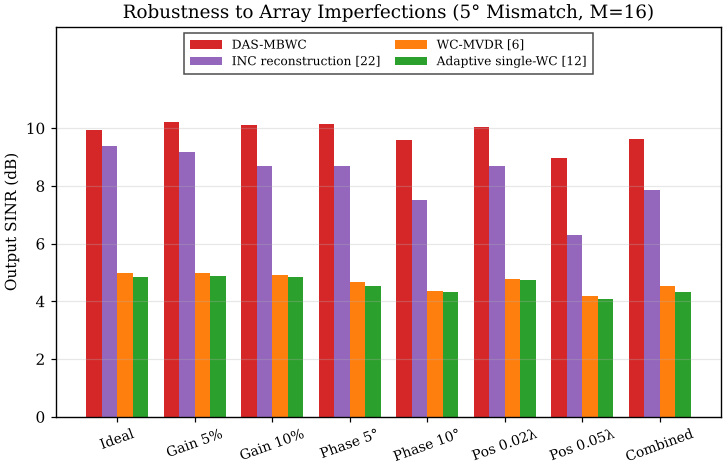

{
 "Ideal": {
  "DAS-MBWC": 9.95,
  "INC reconstruction [22]": 9.39,
  "WC-MVDR [6]": 4.96,
  "Adaptive single-WC [12]": 4.84
 },
 "Gain 5%": {
  "DAS-MBWC": 10.23,
  "INC reconstruction [22]": 9.18,
  "WC-MVDR [6]": 4.98,
  "Adaptive single-WC [12]": 4.86
 },
 "Gain 10%": {
  "DAS-MBWC": 10.13,
  "INC reconstruction [22]": 8.67,
  "WC-MVDR [6]": 4.92,
  "Adaptive single-WC [12]": 4.84
 },
 "Phase 5°": {
  "DAS-MBWC": 10.15,
  "INC reconstruction [22]": 8.7,
  "WC-MVDR [6]": 4.68,
  "Adaptive single-WC [12]": 4.53
 },
 "Phase 10°": {
  "DAS-MBWC": 9.61,
  "INC reconstruction [22]": 7.52,
  "WC-MVDR [6]": 4.37,
  "Adaptive single-WC [12]": 4.32
 },
 "Pos 0.02λ": {
  "DAS-MBWC": 10.06,
  "INC reconstruction [22]": 8.69,
  "WC-MVDR [6]": 4.77,
  "Adaptive single-WC [12]": 4.73
 },
 "Pos 0.05λ": {
  "DAS-MBWC": 8.98,
  "INC reconstruction [22]": 6.3,
  "WC-MVDR [6]": 4.2,
  "Adaptive single-WC [12]": 4.06
 },
 "Combined": {
  "DAS-MBWC": 9.61,
  "INC reconstruction [22]": 7.87,
  "WC-MVDR 

In [13]:
fig_3_11()
show('Fig3.11')

## Figure 3.12: array size scaling at 7° mismatch

Six-point constraint fan from the true direction (0°, bound 1.9) to 8.75° (bounds 1.3), bounds and radius scaled by the square root of M/16; reconstruction sector ±7° about the presumed direction. Right panel: one interferer at 12°, inside the declared region. 15 trials per case.

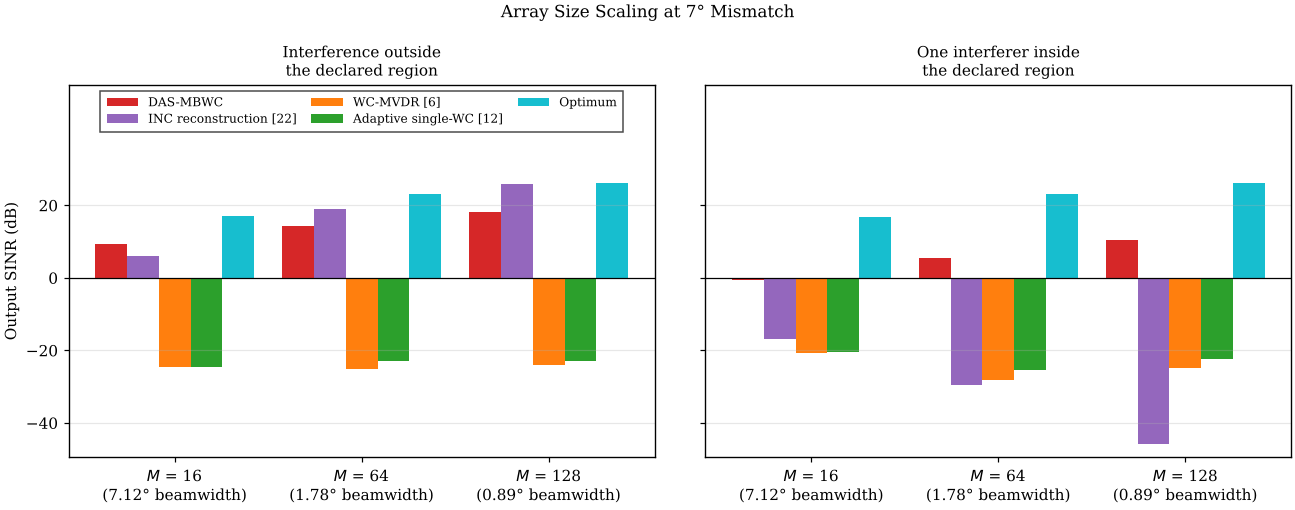

{
 "Interference outside the declared region": {
  "DAS-MBWC": {
   "16": 9.27,
   "64": 14.22,
   "128": 18.3
  },
  "INC reconstruction [22]": {
   "16": 5.95,
   "64": 18.99,
   "128": 25.92
  },
  "WC-MVDR [6]": {
   "16": -24.44,
   "64": -25.07,
   "128": -24.03
  },
  "Adaptive single-WC [12]": {
   "16": -24.54,
   "64": -22.83,
   "128": -22.89
  },
  "Optimum": {
   "16": 17.02,
   "64": 23.06,
   "128": 26.07
  }
 },
 "One interferer inside the declared region": {
  "DAS-MBWC": {
   "16": -0.59,
   "64": 5.54,
   "128": 10.43
  },
  "INC reconstruction [22]": {
   "16": -16.98,
   "64": -29.67,
   "128": -45.91
  },
  "WC-MVDR [6]": {
   "16": -20.58,
   "64": -28.14,
   "128": -24.8
  },
  "Adaptive single-WC [12]": {
   "16": -20.53,
   "64": -25.43,
   "128": -22.45
  },
  "Optimum": {
   "16": 16.89,
   "64": 23.05,
   "128": 26.07
  }
 }
}


In [14]:
fig_3_12()
show('Fig3.12')

## Figure 3.13: sensitivity of the bound adaptation (3.20)

Point source at 5° mismatch; each parameter swept about its nominal value (dotted line) with the others fixed; 15 trials per setting.

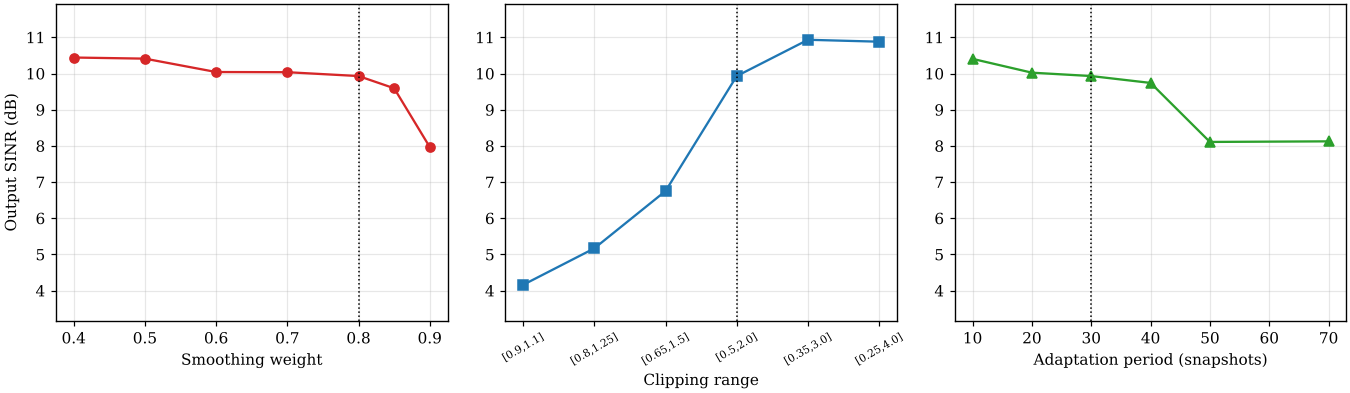

{
 "smoothing_weight": {
  "0.4": 10.44,
  "0.5": 10.41,
  "0.6": 10.04,
  "0.7": 10.04,
  "0.8": 9.93,
  "0.85": 9.59,
  "0.9": 7.97
 },
 "clipping_range": {
  "[0.9, 1.1]": 4.16,
  "[0.8, 1.25]": 5.17,
  "[0.65, 1.5]": 6.75,
  "[0.5, 2.0]": 9.93,
  "[0.35, 3.0]": 10.93,
  "[0.25, 4.0]": 10.88
 },
 "adaptation_period": {
  "10": 10.4,
  "20": 10.02,
  "30": 9.93,
  "40": 9.74,
  "50": 8.11,
  "70": 8.12
 }
}


In [15]:
fig_3_13()
show('Fig3.13')

## Figure 3.14: measured computation time

Complete DAS-MBWC recursion (100-snapshot run, median of 5 repetitions) against one exact WC-MVDR weight solve on a fixed covariance (median of 5 repetitions of 20 solves). Timings depend on the machine.

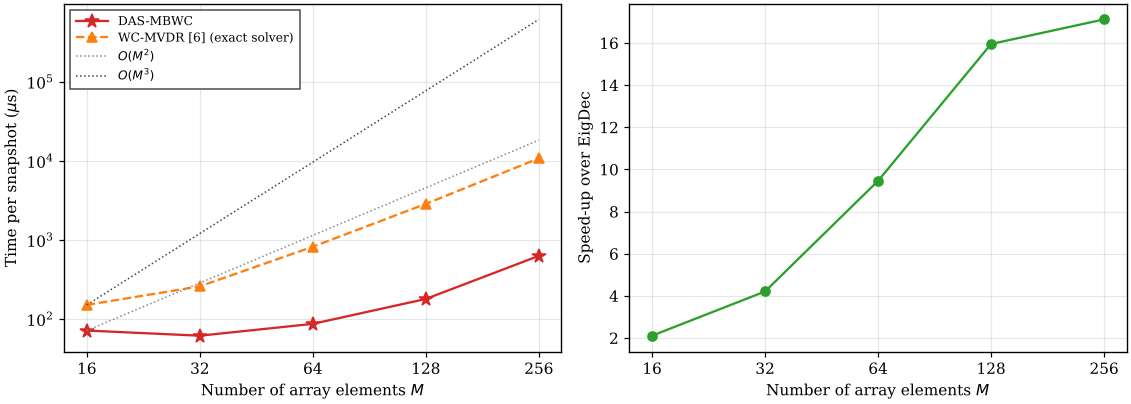

{
 "environment": {
  "machine": "x86_64",
  "cores": 2,
  "python": "3.13.18",
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "cvxpy": "1.9.3",
  "scs": "3.3.2",
  "cpu": "Intel(R) Xeon(R) Processor @ 2.10GHz"
 },
 "rows": [
  {
   "M": 16,
   "das_mbwc_us_per_snapshot": 71.5,
   "wc_mvdr_us_per_solve": 150.9,
   "speedup": 2.1
  },
  {
   "M": 32,
   "das_mbwc_us_per_snapshot": 61.5,
   "wc_mvdr_us_per_solve": 258.9,
   "speedup": 4.2
  },
  {
   "M": 64,
   "das_mbwc_us_per_snapshot": 86.8,
   "wc_mvdr_us_per_solve": 821.5,
   "speedup": 9.5
  },
  {
   "M": 128,
   "das_mbwc_us_per_snapshot": 179.4,
   "wc_mvdr_us_per_solve": 2862.3,
   "speedup": 16.0
  },
  {
   "M": 256,
   "das_mbwc_us_per_snapshot": 629.3,
   "wc_mvdr_us_per_solve": 10775.9,
   "speedup": 17.1
  }
 ]
}


In [16]:
fig_3_14()
show('Fig3.14')

## Tables 3.2–3.6

Table 3.2: final-snapshot SINR, 25 trials. Table 3.3: DAS-MBWC against the SCS solution of (3.12) at the reference bounds on the batch covariance at the final snapshot of every Table 3.2 trial. Table 3.4: one SCS solve of (3.12) against the DAS-MBWC Gram correction (timings depend on the machine). Table 3.5: constraint placement under large angular spread. Table 3.6: stability of the recursion (snapshots 150–299 of 25 trials; five runs of 3000 snapshots).

In [17]:
table_3_2()
show('Table3.2')

{
 "2° point source": {
  "Std MVDR": -11.0,
  "DL-MVDR": -2.2,
  "WC [6]": 13.6,
  "1-WC [12]": 13.5,
  "INC [22]": 16.0,
  "All-constr.": 11.6,
  "DAS-MBWC": 11.6,
  "Optimum": 17.0
 },
 "2° sm. spread": {
  "Std MVDR": 6.7,
  "DL-MVDR": 9.8,
  "WC [6]": 14.2,
  "1-WC [12]": 14.2,
  "INC [22]": 16.6,
  "All-constr.": 12.8,
  "DAS-MBWC": 12.8,
  "Optimum": 17.6
 },
 "5° point source": {
  "Std MVDR": -22.1,
  "DL-MVDR": -15.7,
  "WC [6]": 4.9,
  "1-WC [12]": 4.8,
  "INC [22]": 9.4,
  "All-constr.": 9.7,
  "DAS-MBWC": 10.2,
  "Optimum": 17.0
 },
 "5° sm. spread": {
  "Std MVDR": 3.0,
  "DL-MVDR": 5.8,
  "WC [6]": 10.0,
  "1-WC [12]": 9.9,
  "INC [22]": 10.2,
  "All-constr.": 11.1,
  "DAS-MBWC": 11.5,
  "Optimum": 17.6
 },
 "5° lg. spread": {
  "Std MVDR": -18.3,
  "DL-MVDR": -13.9,
  "WC [6]": 5.0,
  "1-WC [12]": 4.8,
  "INC [22]": 9.6,
  "All-constr.": 9.8,
  "DAS-MBWC": 10.3,
  "Optimum": 17.0
 },
 "7° point source": {
  "Std MVDR": -25.1,
  "DL-MVDR": -24.8,
  "WC [6]": -25.7,
  "1-

In [18]:
table_3_3()
show('Table3.3')

{
 "2° point source": {
  "DAS-MBWC": 11.6,
  "SOCP": 12.5,
  "difference": -0.88,
  "difference_ci95": 0.28,
  "solver_status": {
   "optimal": 25
  },
  "max_constraint_residual": 8.45038660215458e-05
 },
 "2° sm. spread": {
  "DAS-MBWC": 12.8,
  "SOCP": 13.6,
  "difference": -0.81,
  "difference_ci95": 0.33,
  "solver_status": {
   "optimal": 25
  },
  "max_constraint_residual": 4.161881261222078e-05
 },
 "5° point source": {
  "DAS-MBWC": 10.2,
  "SOCP": 10.4,
  "difference": -0.2,
  "difference_ci95": 0.15,
  "solver_status": {
   "optimal": 25
  },
  "max_constraint_residual": 7.382429159630277e-05
 },
 "5° sm. spread": {
  "DAS-MBWC": 11.5,
  "SOCP": 11.8,
  "difference": -0.36,
  "difference_ci95": 0.21,
  "solver_status": {
   "optimal": 25
  },
  "max_constraint_residual": 5.441751786250393e-05
 },
 "5° lg. spread": {
  "DAS-MBWC": 10.3,
  "SOCP": 10.5,
  "difference": -0.18,
  "difference_ci95": 0.21,
  "solver_status": {
   "optimal": 25
  },
  "max_constraint_residual": 8.

In [19]:
table_3_4()
show('Table3.4')

{
 "environment": {
  "machine": "x86_64",
  "cores": 2,
  "python": "3.13.18",
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "cvxpy": "1.9.3",
  "scs": "3.3.2",
  "cpu": "Intel(R) Xeon(R) Processor @ 2.10GHz"
 },
 "rows": {
  "16": {
   "SCS_ms": 1.47,
   "SCS_wall_ms": 10.39,
   "DAS_MBWC_ms": 0.0224,
   "speedup": 66.0,
   "corrections_timed": 295
  },
  "32": {
   "SCS_ms": 2.84,
   "SCS_wall_ms": 13.83,
   "DAS_MBWC_ms": 0.0261,
   "speedup": 109.0,
   "corrections_timed": 300
  },
  "64": {
   "SCS_ms": 5.95,
   "SCS_wall_ms": 20.26,
   "DAS_MBWC_ms": 0.0296,
   "speedup": 201.0,
   "corrections_timed": 300
  },
  "128": {
   "SCS_ms": 17.12,
   "SCS_wall_ms": 49.56,
   "DAS_MBWC_ms": 0.0341,
   "speedup": 503.0,
   "corrections_timed": 300
  }
 }
}


In [20]:
table_3_5()
show('Table3.5')

{
 "Point grid near presumed dir.": {
  "5°": 10.3,
  "7°": 6.8
 },
 "Point grid + multipath dirs (−25°, +35°)": {
  "5°": 8.9,
  "7°": 7.1
 },
 "Point grid + constraint at +44°": {
  "5°": -1.0,
  "7°": -4.5
 },
 "Point grid + constraints on interferers (45°, −60°)": {
  "5°": -3.9,
  "7°": -6.9
 }
}


In [21]:
table_3_6()
show('Table3.6')

{
 "2° point source": {
  "SINR s.d. (dB)": 0.79,
  "Set change rate": 0.0,
  "Two-cycle fraction": 0.0,
  "Mean |A|": 4.0,
  "Resets without": 2.0,
  "Resets with": 0.0,
  "SINR last 500 (dB)": 13.2,
  "max ||w|| with rescaling": 998565287398.2823
 },
 "2° sm. spread": {
  "SINR s.d. (dB)": 0.86,
  "Set change rate": 0.0,
  "Two-cycle fraction": 0.0,
  "Mean |A|": 4.0,
  "Resets without": 2.0,
  "Resets with": 0.0,
  "SINR last 500 (dB)": 13.9,
  "max ||w|| with rescaling": 998553142892.3965
 },
 "5° point source": {
  "SINR s.d. (dB)": 0.87,
  "Set change rate": 0.546,
  "Two-cycle fraction": 0.395,
  "Mean |A|": 3.05,
  "Resets without": 2.0,
  "Resets with": 0.0,
  "SINR last 500 (dB)": 10.6,
  "max ||w|| with rescaling": 998410799638.8569
 },
 "5° sm. spread": {
  "SINR s.d. (dB)": 0.84,
  "Set change rate": 0.59,
  "Two-cycle fraction": 0.409,
  "Mean |A|": 3.07,
  "Resets without": 2.0,
  "Resets with": 0.0,
  "SINR last 500 (dB)": 11.9,
  "max ||w|| with rescaling": 99989674595

## Numbers quoted in the text

Steering-vector distances (Section 3.2), clairvoyant optimum, Table 3.2 with 200 trials (Section 3.6), Slater margin and feasibility limits of the grid and of its subsets (Appendix 3.A.4), the bound ramp (Section 3.4.5), the fixed-bound ablation (Section 3.4.5), the correction-to-weight ratio (Section 3.4.7), the constraint residual of the returned weight (Section 3.6.6) and the signed-mismatch sweep (Section 3.6).

In [22]:
text_checks()
show('text')

{
 "steering_distances": {
  "0-1 deg": 1.9,
  "0-2 deg": 3.59,
  "0-3 deg": 4.92,
  "0-5 deg": 6.13,
  "0-7 deg": 5.73
 },
 "steering_distance_7deg_to_constraint_at_3deg": 4.92,
 "clairvoyant_optimum_dB": {
  "point source": 17.0,
  "small spread": 17.6,
  "large spread": 17.0
 },
 "Table3.2_with_200_trials": {
  "2° point source": {
   "Std MVDR": [
    -11.44,
    0.25
   ],
   "DL-MVDR": [
    -2.21,
    0.11
   ],
   "WC [6]": [
    13.61,
    0.04
   ],
   "1-WC [12]": [
    13.57,
    0.06
   ],
   "INC [22]": [
    16.02,
    0.0
   ],
   "DAS-MBWC": [
    11.76,
    0.12
   ],
   "All-constr.": [
    11.75,
    0.11
   ]
  },
  "2° sm. spread": {
   "Std MVDR": [
    6.76,
    0.1
   ],
   "DL-MVDR": [
    9.87,
    0.06
   ],
   "WC [6]": [
    14.27,
    0.03
   ],
   "1-WC [12]": [
    14.21,
    0.05
   ],
   "INC [22]": [
    16.63,
    0.0
   ],
   "DAS-MBWC": [
    12.72,
    0.15
   ],
   "All-constr.": [
    12.72,
    0.15
   ]
  },
  "5° point source": {
   "Std MVD